<a href="https://colab.research.google.com/github/MaVee06/SUPPexam/blob/main/WOMEN_SAFETY_22405062_A_VILAKAZI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Women-Safety Hotspots in Ekurhuleni - Machine Learning Project**

A. Vilakazi

22405062



**INTRODUCTION**

This project investigates recorded crime patterns relevant to women's safety in Ekurhuleni, Gauteng, with a particular focus on Kempton Park. Using South African Police Service SAPS quarterly crime statistics, the project aims to classify police station areas according to selected crime indicators, explore spatial and temporal patterns, and compare machine learning classification models. The findings will be presented through an interactive Streamlit dashboard to support data-driven exploration of recorded crime patterns.

**Problem Statement**

Women’s safety is an important concern, and understanding patterns in recorded crime can help identify areas that may require further investigation and targeted safety interventions. In Ekurhuleni District, South Africa, analysing crime statistics across police stations can provide insight into the distribution of selected crimes associated with potential safety concerns.

This project uses South African Police Service (SAPS) crime statistics and police station location data to explore recorded crime patterns across Ekurhuleni. The selected indicators include rape, sexual assault, murder, attempted murder, kidnapping, common robbery, and robbery with aggravating circumstances.

The project applies data cleaning, exploratory data analysis, data visualisation, and K-Means clustering to identify patterns and group police stations according to similarities in their recorded crime counts. The results are intended to support further investigation and provide a starting point for a visual dashboard that communicates these patterns clearly.

However, the available SAPS statistics are aggregated at police-station level and do not consistently identify the gender of victims or the exact locations of individual incidents. Therefore, the selected crimes are used as indicators relevant to exploring potential women-safety concerns; they cannot be treated as confirmed crimes against women. Police station coordinates represent station locations rather than the actual locations where crimes occurred.

# Project Objectives

The objectives of this project are to:

1. Collect and prepare SAPS quarterly crime statistics and police station location data relevant to Ekurhuleni District.
2. Clean and filter the datasets to focus on police-station-level records within Ekurhuleni.
3. Explore recorded crime patterns using selected crime indicators, including rape, sexual assault, murder, attempted murder, kidnapping, common robbery, and robbery with aggravating circumstances.
4. Use visualisations to compare crime counts across police stations and crime categories.
5. Apply K-Means clustering to group police stations with similar patterns in recorded crime counts.
6. Evaluate clustering performance using silhouette scores to compare two, three, and four clusters.
7. Develop a Streamlit dashboard to present the analysis and clustering results in an accessible format.
8. Discuss the findings, limitations of the data, and possible implications for further women-safety research.

**Importing Libraries**

Python libraries for data manipulation, numerical processing, visualisation, mapping, and machine learning.

Pandas is used to load, clean, filter, group, and transform tabular data.

NumPy supports numerical operations.

Matplotlib is used to create charts and graphs.

Seaborn provides additional statistical visualisation tools.

Regular expressions (re) can be used to clean or standardise text.

OS supports file and directory operations.

Scikit-learn provides the scaling, K-Means clustering, and silhouette-score functionality used in the machine learning stage.

Folium, where imported in the notebook, is used to create an interactive map.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os


Uploading My three datasets

links to the raw data for SAPS

File name is 2026-2027 1st_quater_web.xlsm

https://www.saps.gov.za/services/crimestats.php
This dataset contains the quartly repots covering april to june across the available historical years, with relatively high counts of seleted crime indicators.

File name : 2025-2026 - 4th_quarter_ web.xlsx https://www.saps.gov.za/services/older_crimestats.php
Contains reported crime for the fourth quarer covering Jan - march across the avalible historical years . i will use this as historical data alomg side with the first datasetto compare the crime patterns across two quaters.

File name : Police Station Coordinates source: open.Africa https://open.africa/dataset/police-station-coordinates
This dataset provides geograpical information about police statons. The coordinate data will be matched to the SAPS crime stats using the standardised police station names

In [40]:
df_q1 = pd.read_excel( "/content/drive/MyDrive/2026-2027_-_1st_Quarter_WEB.xlsm",
                     sheet_name= "RAW Data",
                       header=2
                       )
df_q4 = pd.read_excel ("/content/drive/MyDrive/2025-2026_-_4th_Quarter_WEB.xlsx",
                      sheet_name="RAW Data",
                       header=2
                       )
df_coords = pd.read_csv("/content/drive/MyDrive/geo_export_b681af05_ce59_42e8_87e6_41af282b0a6e.csv")

**Data Understanding**

 The datasets are inspected to understand their structure, column names, data types, and contents before analysis begins.

The SAPS datasets contain information such as the level of comparison, police station, district, crime category, and recorded crime counts for the relevant reporting period. The coordinates dataset contains station names and geographical coordinates.

The comp_level column identifies the level at which a crime record is reported. The station column identifies the police station, while district identifies the relevant district. The crime_category column describes the type of offence, and the quarterly total column contains the recorded count for that offence during the reporting period.

The compnt_nm column in the coordinates dataset contains station names. The location_x and location_y columns represent longitude and latitude, respectively.

Inspecting these fields helps determine which columns are required for filtering, analysis, clustering, and mapping.

In [5]:
print("Quarter 1 dataset shape:", df_q1.shape)
print("Quarter 4 dataset shape:", df_q4.shape)
print("Police coordinates dataset shape:", df_coords.shape)

Quarter 1 dataset shape: (55764, 36)
Quarter 4 dataset shape: (55764, 36)
Police coordinates dataset shape: (1140, 6)


In [6]:
print("Quarter 1 columns:")
print(df_q1.columns.tolist())
print("\nQuarter 4  columns:")
print(df_q4.columns.tolist())
print("\nPolice coordinates  columns:")
print(df_coords.columns.tolist())

Quarter 1 columns:
['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Comparison - 1st quarter (April to June - 2022 to 2026)', 'Unnamed: 8', 8, 9, 10, 'Unnamed: 12', 21, 22, 23, 'Unnamed: 16', 34, 35, 36, 'Unnamed: 20', 47, 48, 49, 'Unnamed: 24', 60, 61, 62, 'Unnamed: 28', 76, 73, 77, 74, 79, 80, 'Unnamed: 35']

Quarter 4  columns:
['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Comparison - 4th quarter (January to March - 2022 to 2026)', 'Unnamed: 8', 8, 9, 10, 'Unnamed: 12', 21, 22, 23, 'Unnamed: 16', 34, 35, 36, 'Unnamed: 20', 47, 48, 49, 'Unnamed: 24', 60, 61, 62, 'Unnamed: 28', 76, 73, 77, 74, 79, 80, 'Unnamed: 35']

Police coordinates  columns:
['the_geom', 'compnt_nm', 'create_dt', 'location_x', 'location_y', 'version']


In [7]:
print("Quarter 1 first five rows:")
print(df_q1.head())
print("\nQuarter 4 first five rows:")
print(df_q4.head())
print("\nPolice coordinates first five rows:")
print(df_coords.head())

Quarter 1 first five rows:
                                        Unnamed: 0  \
0                                              NaN   
1  Crime_Category National contribution\nplacement   
2                               Murder Station 439   
3                     Attempted murder Station 363   
4                    Culpable homicide Station 479   

                                          Unnamed: 1  Unnamed: 2  \
0                                                NaN         NaN   
1  Crime_Category Provincial contribution\nplacement  Comp level   
2                       Mpumalanga Murder Station 29     Station   
3             Mpumalanga Attempted murder Station 17     Station   
4            Mpumalanga Culpable homicide Station 45     Station   

                    Unnamed: 3 Unnamed: 4          Unnamed: 5  Unnamed: 6  \
0                          NaN        NaN                 NaN         NaN   
1       Station Crime_Category    Station            District    Province   
2       

In [8]:
print("Quarter 1 data types:")
print(df_q1.dtypes)
print("\nQuarter 4 data types:")
print(df_q4.dtypes)
print("\nPolice coordinates data types:")
print(df_coords.dtypes)

Quarter 1 data types:
Unnamed: 0                                                 object
Unnamed: 1                                                 object
Unnamed: 2                                                 object
Unnamed: 3                                                 object
Unnamed: 4                                                 object
Unnamed: 5                                                 object
Unnamed: 6                                                 object
Comparison - 1st quarter (April to June - 2022 to 2026)    object
Unnamed: 8                                                 object
8                                                          object
9                                                          object
10                                                         object
Unnamed: 12                                                object
21                                                         object
22                                                    

Missing values

In [9]:
print("Quarter 1 missing values:")
print(df_q1.isnull().sum())
print("\nQuarter 4 missing values:")
print(df_q4.isnull().sum())
print("\nPolice coordinates missing values:")
print(df_coords.isnull().sum())

Quarter 1 missing values:
Unnamed: 0                                                    8
Unnamed: 1                                                    9
Unnamed: 2                                                    8
Unnamed: 3                                                    8
Unnamed: 4                                                    8
Unnamed: 5                                                    8
Unnamed: 6                                                    9
Comparison - 1st quarter (April to June - 2022 to 2026)    1246
Unnamed: 8                                                 1247
8                                                          1247
9                                                          1247
10                                                         1247
Unnamed: 12                                                1247
21                                                         1247
22                                                         1247
23            

In [10]:
print("Duplicate rows in Quarter 1:",
df_q1.duplicated().sum())
print("Duplicate rows in Quarter 4:",
df_q4.duplicated().sum())
print("Duplicate rows in Police coordinates:",
df_coords.duplicated().sum())

Duplicate rows in Quarter 1: 5
Duplicate rows in Quarter 4: 5
Duplicate rows in Police coordinates: 0


Checking Police stations

In [12]:
print("Number of Police Stations:",
df_coords["compnt_nm"].nunique())
print("\nPolice Stations names:")
print(df_coords["compnt_nm"].unique())
print("\nFirst 5 Police stations  :")
print(df_coords.head())


Number of Police Stations: 1140

Police Stations names:
['KOLOMANE' 'COLESBERG' 'NAVALSIG' ... 'DARLING' 'EENDEKUIL' 'KIRSTENHOF']

First 5 Police stations  :
                                            the_geom   compnt_nm  create_dt  \
0  0101000020E6100000911A4CC3F0C93A4047C5387F1336...    KOLOMANE   20140207   
1  0101000020E6100000BFC7D2872E1839406CEE5A423EB8...   COLESBERG   20140207   
2  0101000020E6100000FEE461A1D63C3A4066D72FD80D1B...    NAVALSIG   20140207   
3  0101000020E6100000FE5D11FC6F7D3B40BB847CD0B375...     NDEVANA   20140207   
4  0101000020E61000004FF949B54FB73A40B9506B9A773C...  BOTSHABELO   20140207   

   location_x  location_y version  
0    26.78883   -32.42247   1.1.0  
1    25.09446   -30.71970   1.1.0  
2    26.23765   -29.10568   1.1.0  
3    27.48999   -32.91955   1.1.0  
4    26.71606   -29.23620   1.1.0  


In [13]:
print("Quarter 1 columns:")
print(df_q1.columns.tolist())
print("\nQuarter 4  columns:")
print(df_q4.columns.tolist())


Quarter 1 columns:
['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Comparison - 1st quarter (April to June - 2022 to 2026)', 'Unnamed: 8', 8, 9, 10, 'Unnamed: 12', 21, 22, 23, 'Unnamed: 16', 34, 35, 36, 'Unnamed: 20', 47, 48, 49, 'Unnamed: 24', 60, 61, 62, 'Unnamed: 28', 76, 73, 77, 74, 79, 80, 'Unnamed: 35']

Quarter 4  columns:
['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Comparison - 4th quarter (January to March - 2022 to 2026)', 'Unnamed: 8', 8, 9, 10, 'Unnamed: 12', 21, 22, 23, 'Unnamed: 16', 34, 35, 36, 'Unnamed: 20', 47, 48, 49, 'Unnamed: 24', 60, 61, 62, 'Unnamed: 28', 76, 73, 77, 74, 79, 80, 'Unnamed: 35']


**DATA CLEANING**

Data cleaning is necessary to improve consistency and reduce errors during analysis. The column names are standardised by converting them to lowercase, removing unnecessary spaces, and replacing spaces with underscores.

Text values in important columns are also standardised where necessary. This is particularly important for comp_level, because differences in capitalisation or leading and trailing spaces may cause valid station-level records to be excluded by a filter.

After standardising the relevant fields, the datasets are filtered to retain records whose comparison level is Station. This ensures that the analysis focuses on police-station-level records rather than mixing station records with other reporting levels.

The cleaned data is then used in the next stage to isolate records belonging to Ekurhuleni District.

Data preparation also includes checking the availability of required columns and ensuring that crime counts can be used in numerical analysis.

In [14]:
df_q1.columns=(
    df_q1.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

df_q4.columns=(
    df_q4.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

df_coords.columns=(
    df_coords.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print("Quarter 1 columns:")
print(df_q1.columns.tolist())
print("\nQuarter 4  columns:")
print(df_q4.columns.tolist())
print("\nPolice coordinates  columns:")
print(df_coords.columns.tolist())

Quarter 1 columns:
['unnamed:_0', 'unnamed:_1', 'unnamed:_2', 'unnamed:_3', 'unnamed:_4', 'unnamed:_5', 'unnamed:_6', 'comparison_-_1st_quarter_(april_to_june_-_2022_to_2026)', 'unnamed:_8', '8', '9', '10', 'unnamed:_12', '21', '22', '23', 'unnamed:_16', '34', '35', '36', 'unnamed:_20', '47', '48', '49', 'unnamed:_24', '60', '61', '62', 'unnamed:_28', '76', '73', '77', '74', '79', '80', 'unnamed:_35']

Quarter 4  columns:
['unnamed:_0', 'unnamed:_1', 'unnamed:_2', 'unnamed:_3', 'unnamed:_4', 'unnamed:_5', 'unnamed:_6', 'comparison_-_4th_quarter_(january_to_march_-_2022_to_2026)', 'unnamed:_8', '8', '9', '10', 'unnamed:_12', '21', '22', '23', 'unnamed:_16', '34', '35', '36', 'unnamed:_20', '47', '48', '49', 'unnamed:_24', '60', '61', '62', 'unnamed:_28', '76', '73', '77', '74', '79', '80', 'unnamed:_35']

Police coordinates  columns:
['the_geom', 'compnt_nm', 'create_dt', 'location_x', 'location_y', 'version']


check the stations coordinates

In [15]:
print("Number of unique police stations:")
print(df_coords["compnt_nm"].nunique())
print("\nDuplicate stations names:")
print(df_coords["compnt_nm"].unique())
print("\nCoordinates data types:")
print(df_coords[["location_x", "location_y"]].dtypes)
print("\nLongitude summary:")
print(df_coords["location_x"].describe())
print("\nLatitude summary:")
print(df_coords["location_y"].describe())

Number of unique police stations:
1140

Duplicate stations names:
['KOLOMANE' 'COLESBERG' 'NAVALSIG' ... 'DARLING' 'EENDEKUIL' 'KIRSTENHOF']

Coordinates data types:
location_x    float64
location_y    float64
dtype: object

Longitude summary:
count    1140.000000
mean       26.761839
std         3.823020
min        16.492180
25%        25.264772
50%        27.876755
75%        29.614123
max        32.743480
Name: location_x, dtype: float64

Latitude summary:
count    1140.000000
mean      -28.969151
std         3.181279
min       -34.800590
25%       -31.673035
50%       -28.747050
75%       -26.227683
max       -22.343310
Name: location_y, dtype: float64


In [23]:
print("Quarter 1 shape:", df_q1.shape)
print("Quarter 4 shape:", df_q4.shape)

print("\nQuarter 1 first 15 rows:")
print(df_q1.head(15).to_string(index=False, header=False))

print("\nQuarter 4 first 15 rows:")
print(df_q4.head(15).to_string(index=False, header=False))

Quarter 1 shape: (55765, 36)
Quarter 4 shape: (55765, 36)

Quarter 1 first 15 rows:
                                               NaN                                                          NaN        NaN                                              NaN       NaN                NaN        NaN Comparison - 1st quarter (April to June - 2022 to 2026)  NaN                   8                   9                  10                       NaN                  21                  22                  23                       NaN                  34                  35                  36                       NaN                  47                  48                  49                       NaN                  60                  61                  62                       NaN                               76                             73                                 77                               74              79                                  80   NaN
                       

Unnecessary columns

In [24]:
print("Quarter 1 columns and missing values:")
print(df_q1.isnull().sum())
print("\nQuarter 4 columns and missing values:")
print(df_q4.isnull().sum())

Quarter 1 columns and missing values:
0        9
1       10
2        9
3        9
4        9
5        9
6       10
7     1246
8     1248
9     1247
10    1247
11    1247
12    1248
13    1247
14    1247
15    1247
16    1248
17    1247
18    1247
19    1247
20    1248
21    1247
22    1247
23    1247
24    1248
25    1247
26    1247
27    1247
28    1248
29    1247
30    1247
31    1247
32    1247
33    1247
34    1247
35    1248
dtype: int64

Quarter 4 columns and missing values:
0        9
1       10
2        9
3        9
4        9
5        9
6       10
7     1246
8     1248
9     1247
10    1247
11    1247
12    1248
13    1247
14    1247
15    1247
16    1248
17    1247
18    1247
19    1247
20    1248
21    1247
22    1247
23    1247
24    1248
25    1247
26    1247
27    1247
28    1248
29    1247
30    1247
31    1247
32    1247
33    1247
34    1247
35    1248
dtype: int64


droping empty columns

In [25]:
df_q1.dropna(axis=1, how="all", inplace=True)
df_q4.dropna(axis=1, how="all", inplace=True)

print("Quarter 1 shape after removing empty columns:", df_q1.shape)
print("Quarter 4 shape after removing empty columns:", df_q4.shape)

Quarter 1 shape after removing empty columns: (55765, 36)
Quarter 4 shape after removing empty columns: (55765, 36)


Removing duplicated rows

In [26]:
df_q1.drop_duplicates(inplace=True)
df_q4.drop_duplicates(inplace=True)
df_coords.drop_duplicates(inplace=True)

print("Quarter 1 shape after removing duplicates:", df_q1.shape)
print("Quarter 4 shape after removing duplicates:", df_q4.shape)
print("Police coordinates shape after removing duplicates:", df_coords.shape)

Quarter 1 shape after removing duplicates: (55760, 36)
Quarter 4 shape after removing duplicates: (55760, 36)
Police coordinates shape after removing duplicates: (1140, 6)


Removing unnecessary rows





In [30]:
print("Quarter 1 missing station names:")
print(df_q1["station"].isnull().sum())
print("\nQuarter 4 missing station names:")
print(df_q4["station"].isnull().sum())
print("\nQuarter 1 stations name examples:")
print(df_coords["station"].dropna().head(10).tolist())
print("\nQuarter 4 stations name examples:")
print(df_coords["station"].dropna().head(10).tolist())
#had changed the header earlier from 2 to None so that was the cause of this error

Quarter 1 missing station names:


KeyError: 'station'

In [32]:
print(df_q1.columns.tolist())
print(df_q4.columns.tolist())


['Crime_Category National contribution\nplacement', 'Crime_Category Provincial contribution\nplacement', 'Comp level', 'Station Crime_Category', 'Station', 'District', 'Province', 'Crime_Category', 'Code', datetime.datetime(2022, 4, 1, 0, 0), datetime.datetime(2022, 5, 1, 0, 0), datetime.datetime(2022, 6, 1, 0, 0), 'April 2022 to \nJune 2022', datetime.datetime(2023, 4, 1, 0, 0), datetime.datetime(2023, 5, 1, 0, 0), datetime.datetime(2023, 6, 1, 0, 0), 'April 2023 to \nJune 2023', datetime.datetime(2024, 4, 1, 0, 0), datetime.datetime(2024, 5, 1, 0, 0), datetime.datetime(2024, 6, 1, 0, 0), 'April 2024 to \nJune 2024', datetime.datetime(2025, 4, 1, 0, 0), datetime.datetime(2025, 5, 1, 0, 0), datetime.datetime(2025, 6, 1, 0, 0), 'April 2025 to \nJune 2025', datetime.datetime(2026, 4, 1, 0, 0), datetime.datetime(2026, 5, 1, 0, 0), datetime.datetime(2026, 6, 1, 0, 0), 'April 2026 to \nJune 2026', 'National contribution\nplacement', 'National count diff\nplacement', 'Provincial contribution

In [34]:

df_q1.columns = (
    df_q1.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

df_q4.columns = (
    df_q4.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

print(df_q1.columns.tolist())

['crime_category_national_contribution_placement', 'crime_category_provincial_contribution_placement', 'comp_level', 'station_crime_category', 'station', 'district', 'province', 'crime_category', 'code', '2022-04-01_00:00:00', '2022-05-01_00:00:00', '2022-06-01_00:00:00', 'april_2022_to_june_2022', '2023-04-01_00:00:00', '2023-05-01_00:00:00', '2023-06-01_00:00:00', 'april_2023_to_june_2023', '2024-04-01_00:00:00', '2024-05-01_00:00:00', '2024-06-01_00:00:00', 'april_2024_to_june_2024', '2025-04-01_00:00:00', '2025-05-01_00:00:00', '2025-06-01_00:00:00', 'april_2025_to_june_2025', '2026-04-01_00:00:00', '2026-05-01_00:00:00', '2026-06-01_00:00:00', 'april_2026_to_june_2026', 'national_contribution_placement', 'national_count_diff_placement', 'provincial_contribution_placement', 'provincial_count_diff_placement', 'count_direction', 'count_offence_group', 'no']


In [35]:
df_q1.dropna(subset=["station"], inplace=True)
df_q4.dropna(subset=["station"], inplace=True)

print("Quarter 1 shape after removing rows without stations:", df_q1.shape)
print("Quarter 4 shape after removing rows without stations:", df_q4.shape)

Quarter 1 shape after removing rows without stations: (55755, 36)
Quarter 4 shape after removing rows without stations: (55755, 36)


In [36]:
df_q1.drop_duplicates(inplace=True)
df_q4.drop_duplicates(inplace=True)
df_coords.drop_duplicates(inplace=True)

print("Quarter 1 final shape:", df_q1.shape)
print("Quarter 4 final shape:", df_q4.shape)
print("Police coordinates final shape:", df_coords.shape)

Quarter 1 final shape: (55755, 36)
Quarter 4 final shape: (55755, 36)
Police coordinates final shape: (1140, 6)


Below we checking the data structure .

we checking
comp_level
stations
crime_category
coordinate columns

In [37]:
print("Record types in Quarter 1:")
print(df_q1["comp_level"].value_counts(dropna=False))
print("\nFirst 10 records:")
display(df_q4[
    ["comp_level", "station", "crime_category"]
].head(10))
print("\nPolice coordinates columns:")
print(df_coords.columns.tolist())

Record types in Quarter 1:
comp_level
Station      51656
District      2420
Province       396
7              192
6              177
5              169
8              147
4              134
9              113
3               81
10              81
2               44
National        44
11              33
1               28
12              14
0               10
13               7
14               5
-200000          3
Increased        1
Name: count, dtype: int64

First 10 records:


,comp_level,station,crime_category
0,Station,Acornhoek,Murder
1,Station,Acornhoek,Attempted murder
2,Station,Acornhoek,Culpable homicide
3,Station,Acornhoek,Robbery with aggravating circumstances
4,Station,Acornhoek,Common robbery
5,Station,Acornhoek,Public violence
6,Station,Acornhoek,Rape
7,Station,Acornhoek,Sexual assault
8,Station,Acornhoek,Crimen injuria
9,Station,Acornhoek,Neglect and ill-treatment of children



Police coordinates columns:
['the_geom', 'compnt_nm', 'create_dt', 'location_x', 'location_y', 'version']


Keeping only police station records

In [38]:
df_q1=df_q1[df_q1["comp_level"]==" Station"].copy()
df_q4=df_q4[df_q4["comp_level"]==" Station"].copy()

print("Quarter 1 station records:", df_q1.shape)
print("Quarter 4 station records:", df_q4.shape)

print("\nQuarter 1 record types:")
display(df_q1["comp_level"].value_counts())
print("\nQuarter 4 record types:")
display(df_q4["comp_level"].value_counts())

Quarter 1 station records: (0, 36)
Quarter 4 station records: (0, 36)

Quarter 1 record types:


,count
comp_level,



Quarter 4 record types:


,count
comp_level,


In [39]:
print("Quarter 1 crime categories:")
print(sorted(df_q1["crime_category"].dropna().unique()))
print("\nQuarter 4 crime categories:")
print(df_q4["crime_category"].dropna().unique())


Quarter 1 crime categories:
[]

Quarter 4 crime categories:
[]


In [43]:
df_q1= pd.read_excel(
    "/content/drive/MyDrive/2026-2027_-_1st_Quarter_WEB.xlsm",
    sheet_name="RAW Data",
    header=2,
)

df_q4= pd.read_excel(
    "/content/drive/MyDrive/2025-2026_-_4th_Quarter_WEB.xlsx",
    sheet_name="RAW Data",
    header=2,
)

for df in[df_q1, df_q4, df_coords]:
 df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

df_q1 = df_q1[
    df_q1["comp_level"].astype(str).str.strip().str.casefold() == " Station"
]

df_q4 = df_q4[
    df_q4["comp_level"].astype(str).str.strip().str.casefold() == " Station"
]

print ("Q1 station records:", df_q1.shape)
print ("Q4 station records:", df_q4.shape)

print("\nDistricts in Q1:")
print (df_q1["district"].dropna().unique())


Q1 station records: (0, 36)
Q4 station records: (0, 36)

Districts in Q1:
[]


it inputing 0 so i wanna see where the problem might be before moving on

In [44]:
df_q1= pd.read_excel(
    "/content/drive/MyDrive/2026-2027_-_1st_Quarter_WEB.xlsm",
    sheet_name="RAW Data",
    header=2,
)

df_q4= pd.read_excel(
    "/content/drive/MyDrive/2025-2026_-_4th_Quarter_WEB.xlsx",
    sheet_name="RAW Data",
    header=2,
)

for df in[df_q1, df_q4, df_coords]:
 df.columns = (
     df.columns.astype(str)
     .str.strip()
     .str.lower()
     .str.replace(r"\s+", "_", regex=True)
 )

 print ("Q1 shape:", df_q1.shape)
 print ("Q4 shape:", df_q4.shape)

 print ("\nQ1 comp_level values:")
 print (df_q1["comp_level"].astype(str).str.strip().str.casefold().value_counts().head(5))

 print ("\nQ1 first five comp_level values:")
 print (df_q4["comp_level"].head().tolist())

Q1 shape: (55762, 36)
Q4 shape: (55762, 36)

Q1 comp_level values:
comp_level
station     51656
district     2420
province      396
7             192
6             177
Name: count, dtype: int64

Q1 first five comp_level values:


KeyError: 'comp_level'

the code avove had a erroe due to me not commiting the changes i made to q1 to q4 also but trying to fix it

In [45]:
print("Q1 columns:")
print(df_q1.columns.tolist())

print("\nQ4 columns:")
print(df_q4.columns.tolist())

Q1 columns:
['crime_category_national_contribution_placement', 'crime_category_provincial_contribution_placement', 'comp_level', 'station_crime_category', 'station', 'district', 'province', 'crime_category', 'code', '2022-04-01_00:00:00', '2022-05-01_00:00:00', '2022-06-01_00:00:00', 'april_2022_to_june_2022', '2023-04-01_00:00:00', '2023-05-01_00:00:00', '2023-06-01_00:00:00', 'april_2023_to_june_2023', '2024-04-01_00:00:00', '2024-05-01_00:00:00', '2024-06-01_00:00:00', 'april_2024_to_june_2024', '2025-04-01_00:00:00', '2025-05-01_00:00:00', '2025-06-01_00:00:00', 'april_2025_to_june_2025', '2026-04-01_00:00:00', '2026-05-01_00:00:00', '2026-06-01_00:00:00', 'april_2026_to_june_2026', 'national_contribution_placement', 'national_count_diff_placement', 'provincial_contribution_placement', 'provincial_count_diff_placement', 'count_direction', 'count_offence_group', 'no']

Q4 columns:
['Crime_Category National contribution\nplacement', 'Crime_Category Provincial contribution\nplacement'

In [46]:

for df in [df_q1, df_q4]:
    df.columns = [
        str(col).strip().lower().replace("\n", " ").replace(" ", "_")
        for col in df.columns
    ]


df_q1["comp_level"] = df_q1["comp_level"].astype(str).str.strip()
df_q4["comp_level"] = df_q4["comp_level"].astype(str).str.strip()


df_q1 = df_q1[df_q1["comp_level"].str.lower() == "station"]
df_q4 = df_q4[df_q4["comp_level"].str.lower() == "station"]

print("Q1 station records:", df_q1.shape)
print("Q4 station records:", df_q4.shape)

print("\nQ1 districts:")
print(df_q1["district"].dropna().unique())

print("\nQ4 districts:")
print(df_q4["district"].dropna().unique())

Q1 station records: (51656, 36)
Q4 station records: (51656, 36)

Q1 districts:
['Ehlanzeni District' 'Ekurhuleni District' 'Sarah Baartman District'
 'Amathole District' 'Alfred Nzo District' 'Namakwa District'
 'Tshwane District' 'Garden Route District' 'Johannesburg District'
 'Umgungundlovu District' 'Nelson Mandela District' 'Joe Gqabi District'
 'Lejweleputswa District' 'Capricorn District'
 'Dr Ruth Segomotsi Mompati District' 'Uthukela District'
 'eThekwini District' 'Gert Sibande District' 'Sekhukhune District'
 'Thabo Mofutsanyana District' 'Cape Winelands District'
 'Bojanala District' 'Ngaka Modiri Molema District'
 'City of Cape Town District' 'ZF Mgcawu District' 'Zululand District'
 'Mangaung District' 'Vhembe District' 'Frances Baard District'
 'Overberg District' 'John Taolo Gaetsewe District'
 'Buffalo City District' 'Central Karoo District' 'West Rand District'
 'Waterberg District' 'Nkangala District' 'Pixley ka Seme District'
 'Xhariep District' 'OR Tambo District' 

now we filtering for ekurhuleni

After retaining station-level records, both SAPS datasets are filtered to include records belonging to Ekurhuleni District.

The district values are converted to strings, stripped of unnecessary spaces, and compared in lowercase. This makes the filtering process more reliable when the source data contains inconsistent capitalisation or spacing.

The resulting first-quarter dataset contains 1,716 rows before the selected crime categories are extracted. It represents 39 unique police stations in Ekurhuleni District.

Applying the same district filter to the fourth-quarter dataset prepares it for a possible comparison with the first quarter. However, the completed analysis in this notebook currently uses the first-quarter dataset.

Filtering by district ensures that the analysis remains focused on the geographical area defined by the project.

In [48]:
df_q1 = df_q1[
    df_q1["district"].astype(str).str.strip().str.lower() == "ekurhuleni district"]
df_q4 = df_q4[
    df_q4["district"].astype(str).str.strip().str.lower() == "ekurhuleni district"]


print ("Q1 Ekurhuleni records:", df_q1.shape)
print ("Q4 Ekurhuleni records:", df_q4.shape)

print("\nPolice stations in Ekurhuleni:")
print(sorted(df_q1["station"].dropna().unique()))

Q1 Ekurhuleni records: (1716, 36)
Q4 Ekurhuleni records: (1716, 36)

Police stations in Ekurhuleni:
['Actonville', 'Alberton', 'Bedfordview', 'Benoni', 'Boksburg', 'Boksburg North', 'Brackendowns', 'Brakpan', 'Crystalpark', 'Daveyton', 'Dawn Park', 'Devon', 'Duduza', 'Dunnottar', 'Edenpark', 'Edenvale', 'Elsburg', 'Etwatwa', 'Germiston', 'Ivory Park', 'Katlehong', 'Katlehong North', 'Kempton Park', 'Kwa Thema', 'Nigel', 'Norkempark', 'Olifantsfontein', 'Primrose', 'Putfontein', 'Rabie Ridge', 'Reigerpark', 'Sebenza', 'Springs', 'Tembisa', 'Tembisa South', 'Tokoza', 'Tsakane', 'Vosloorus', 'Zonkizizwe']


**Visualisation**

Seven crime categories were selected for the main analysis:

Murder

Attempted murder

Rape

Sexual assault

Kidnapping

Common robbery

Robbery with aggravating circumstances

These indicators were selected because they include offences that may be relevant to broader research into personal safety and violence. They provide a focused set of variables for comparing recorded crime patterns between police stations.

The category names are matched without distinguishing between uppercase and lowercase letters. This helps avoid excluding categories because of differences in text formatting.

The filtered dataset contains 273 records, corresponding to 39 police stations and seven selected crime indicators. The selected data is used for the visualisations, station-level comparison, and K-Means clustering.

An important limitation is that the source data does not consistently identify the gender of the victims. The selected categories must therefore not be interpreted as a count of crimes committed specifically against women.



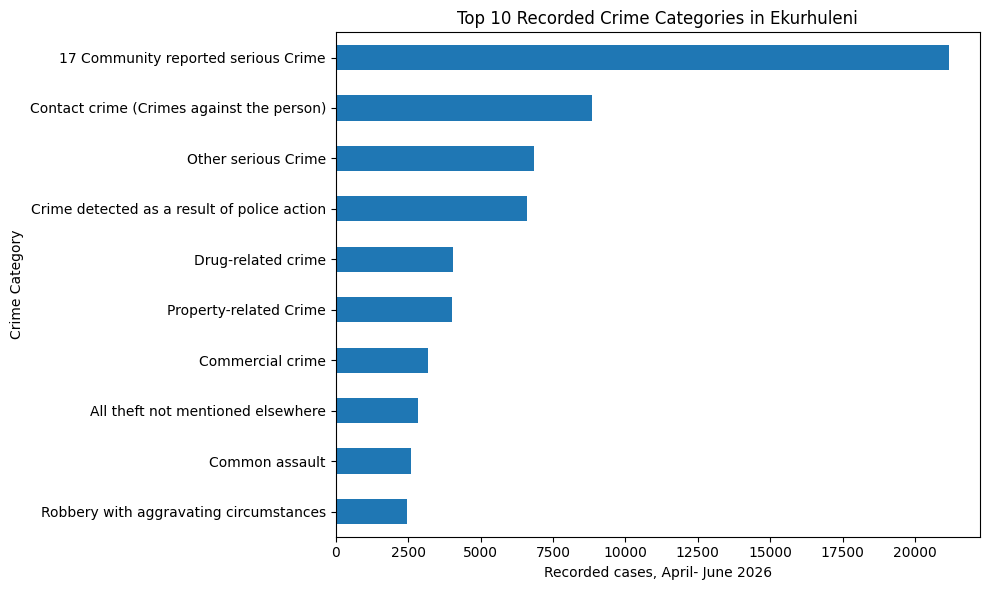

In [49]:
df_q1["april_2026_to_june_2026"] = pd.to_numeric(
    df_q1["april_2026_to_june_2026"], errors="coerce"
)

crime_total =(
    df_q1.groupby("crime_category")["april_2026_to_june_2026"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

crime_total.sort_values().plot(
    kind= "barh",
    figsize=(10, 6)
)

plt.title("Top 10 Recorded Crime Categories in Ekurhuleni")
plt.xlabel("Recorded cases, April- June 2026")
plt.ylabel("Crime Category")
plt.tight_layout()
plt.show()

Exploratory Data Analysis (EDA)


The analysis examines how recorded crime counts differ between crime categories and police stations. It uses summary tables and visualisations to identify categories with higher recorded totals, stations with higher counts across the selected indicators, and differences between individual offence types.

EDA helps identify patterns that may not be immediately obvious in the original tables. It also provides context for interpreting the clusters produced by the machine learning model.

The results describe the recorded counts in the available dataset. Differences between stations may be influenced by factors such as population size, reporting behaviour, and other contextual conditions that are not included in this analysis.

In [51]:
station_totals = (
    crime_data.groupby("station")["april_2026_to_june_2026"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

station_totals.plot(kind="barh", figsize=(9, 5))
plt.title("Top 10 Ekurhuleni Stations for Selected Indicators")
plt.xlabel("Recorded cases (April–June 2026)")
plt.ylabel("Police station")
plt.tight_layout()
plt.show()

# couldn't run because it does not know what the crme data is so i have to first create crime data

NameError: name 'crime_data' is not defined

In [52]:
selected_categories = [
    "Rape",
    "Sexual assault",
    "Attempted murder",
    "Murder",
    "Kidnapping",
    "Common robbery",
    "Robbery with aggravating circumstances"
]

crime_data = df_q1[
    df_q1["crime_category"].astype(str).str.strip().str.casefold()
    .isin([category.casefold() for category in selected_categories])
]

print("Rows available:", len(crime_data))
print("Categories found:", crime_data["crime_category"].unique())


Rows available: 273
Categories found: ['Murder' 'Attempted murder' 'Robbery with aggravating circumstances'
 'Common robbery' 'Rape' 'Sexual assault' 'Kidnapping']


Top 10 Crime Categories

This visualisation presents the ten crime categories with the highest recorded totals in the Ekurhuleni first-quarter dataset.

The chart provides an overview of the distribution of recorded crime across categories and helps show which offences contribute the largest counts in the source data. It also provides context for the narrower analysis of the seven selected indicators.

The ranking is based on recorded counts rather than population-adjusted crime rates. A higher count does not necessarily mean that an offence is more likely to occur to an individual, and the chart does not identify the gender of victims.

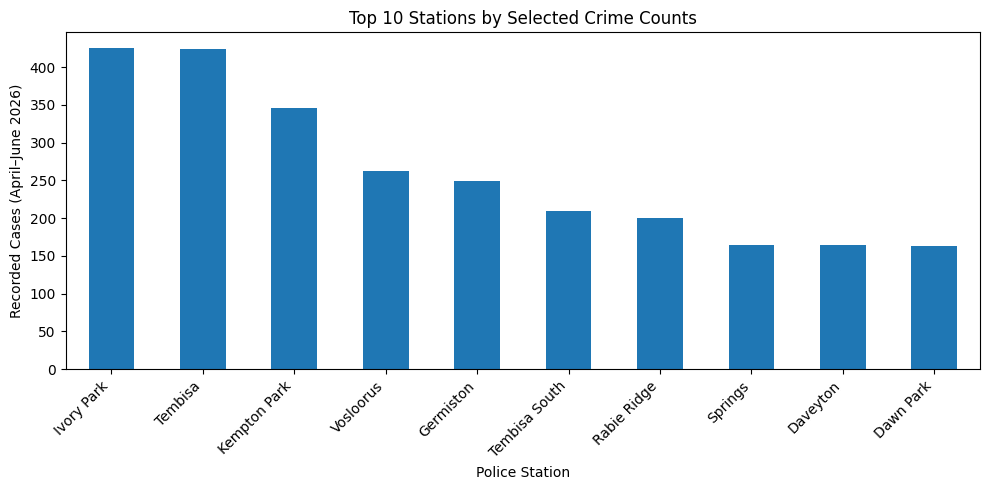

In [53]:

station_totals = (
    crime_data.groupby("station")["april_2026_to_june_2026"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

station_totals.plot(kind="bar", figsize=(10, 5), title="Top 10 Stations by Selected Crime Counts")
plt.xlabel("Police Station")
plt.ylabel("Recorded Cases (April–June 2026)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
#the running code for the erroe above because i have created the crime data cell

In [54]:
df_coords["station_match"] = (
    df_coords["compnt_nm"].astype(str).str.strip().str.casefold()
)

df_q1["station_match"] = (
    df_q1["station"].astype(str).str.strip().str.casefold()
)


station_crimes = (
    crime_data.groupby("station")["april_2026_to_june_2026"]
    .sum()
    .reset_index()
)

station_crimes["station_match"] = (
    station_crimes["station"].astype(str).str.strip().str.casefold()
)


map_data = station_crimes.merge(
    df_coords[["station_match", "location_x", "location_y"]],
    on="station_match",
    how="left"
)

print("Stations analysed:", len(map_data))
print("Stations with matched coordinates:", map_data["location_x"].notna().sum())
print(map_data[["station", "april_2026_to_june_2026", "location_x", "location_y"]]
      .head(10))

Stations analysed: 39
Stations with matched coordinates: 39
          station  april_2026_to_june_2026  location_x  location_y
0      Actonville                     36.0    28.29975   -26.21198
1        Alberton                    129.0    28.12692   -26.26088
2     Bedfordview                     88.0    28.13719   -26.17960
3          Benoni                    125.0    28.31337   -26.19655
4        Boksburg                     90.0    28.23787   -26.22025
5  Boksburg North                    102.0    28.25302   -26.20600
6    Brackendowns                     27.0    28.09636   -26.34619
7         Brakpan                    122.0    28.36257   -26.23481
8     Crystalpark                     44.0    28.37297   -26.12412
9        Daveyton                    165.0    28.41560   -26.15328


**Interactive Crime Heatmap**

An interactive heatmap is created using Folium to display the geographical distribution of the combined counts for the seven selected crime indicators.

The crime data is matched to the police station coordinates using standardised station names. The completed merge matched all 39 analysed stations to their corresponding coordinate records.

The map provides a geographical overview of the station-level results and allows users to explore how the recorded counts vary across the district.

The map uses police station coordinates as reference points. It does not show the precise locations of individual crimes, and the visual intensity represents the selected recorded counts associated with stations rather than confirmed incident locations. It should therefore be used as an exploratory visualisation rather than a precise incident-level crime map.

In [55]:

!pip -q install folium

import folium
from folium.plugins import HeatMap
from IPython.display import display


map_data["location_x"] = pd.to_numeric(map_data["location_x"], errors="coerce")
map_data["location_y"] = pd.to_numeric(map_data["location_y"], errors="coerce")
map_data["april_2026_to_june_2026"] = pd.to_numeric(
    map_data["april_2026_to_june_2026"], errors="coerce"
)

map_data = map_data.dropna(
    subset=["location_x", "location_y", "april_2026_to_june_2026"]
)


crime_map = folium.Map(
    location=[map_data["location_y"].mean(),
              map_data["location_x"].mean()],
    zoom_start=10
)


HeatMap(
    map_data[["location_y", "location_x",
              "april_2026_to_june_2026"]].values.tolist(),
    radius=25,
    blur=18
).add_to(crime_map)


for _, row in map_data.iterrows():
    folium.CircleMarker(
        location=[row["location_y"], row["location_x"]],
        radius=5,
        popup=f"{row['station']}: {row['april_2026_to_june_2026']} recorded cases",
        tooltip=row["station"],
        fill=True
    ).add_to(crime_map)

display(crime_map)


In [56]:

from IPython.display import HTML, display

display(HTML(crime_map._repr_html_()))


i wanted to create a crime map but my notebook does not hav e trust

Crime Categories Across the Top 10 Stations

The stacked bar chart compares the contribution of each selected crime category to the combined recorded counts at the ten highest-ranked police stations.

Each bar represents a police station, while the stacked sections distinguish between the seven crime indicators. This allows the overall recorded count and the composition of that count to be examined together.

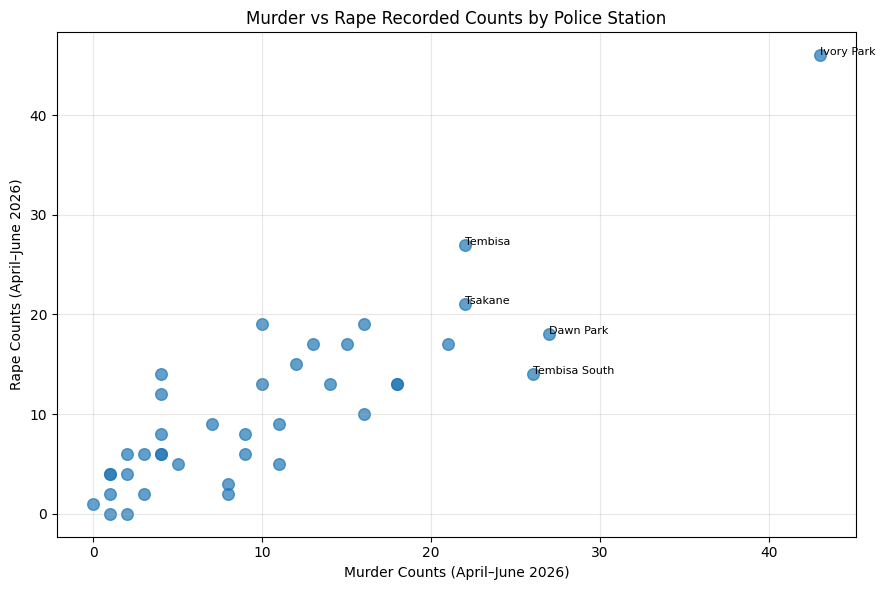

In [57]:


crime_comparison = crime_data.pivot_table(
    index="station",
    columns="crime_category",
    values="april_2026_to_june_2026",
    aggfunc="sum",
    fill_value=0
)


if "Murder" in crime_comparison.columns and "Rape" in crime_comparison.columns:
    plt.figure(figsize=(9, 6))

    plt.scatter(
        crime_comparison["Murder"],
        crime_comparison["Rape"],
        s=70,
        alpha=0.7
    )


    top_stations = (
        crime_comparison["Murder"] + crime_comparison["Rape"]
    ).nlargest(5).index

    for station in top_stations:
        plt.annotate(
            station,
            (crime_comparison.loc[station, "Murder"],
             crime_comparison.loc[station, "Rape"]),
            fontsize=8
        )

    plt.title("Murder vs Rape Recorded Counts by Police Station")
    plt.xlabel("Murder Counts (April–June 2026)")
    plt.ylabel("Rape Counts (April–June 2026)")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("Check category names:", crime_comparison.columns.tolist())


**Distribution of Crime Counts**

The box plot compares the distribution of recorded counts across the seven selected crime categories.

A box plot summarises the spread of values using the median, quartiles, and potential outliers. It helps show whether counts vary considerably between police stations and whether some stations have substantially higher values than others.

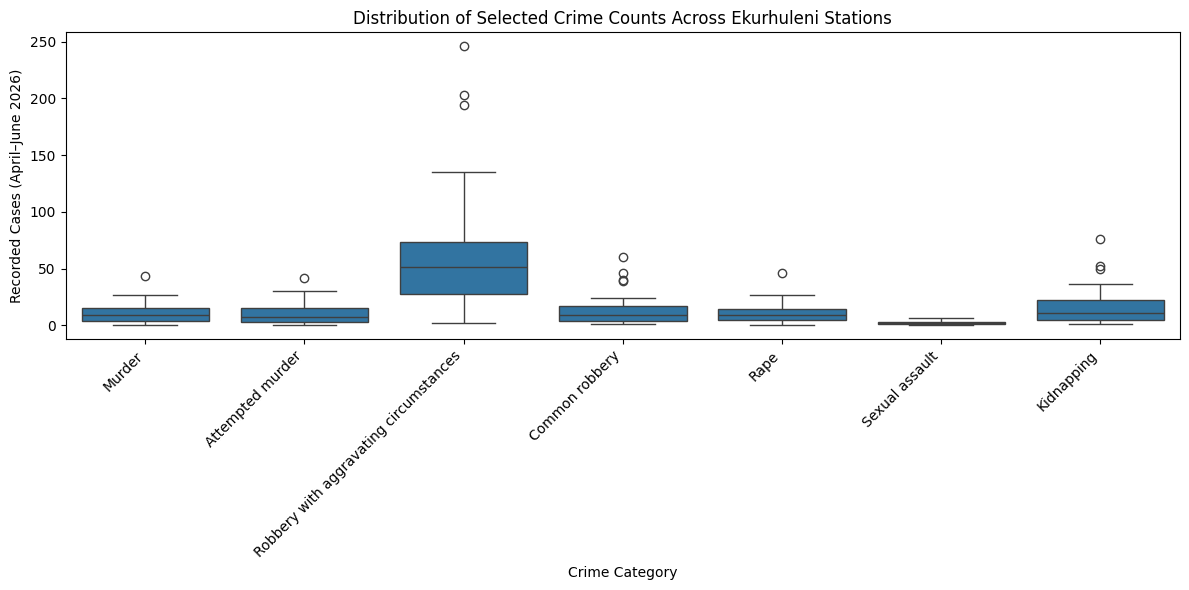

In [58]:

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=crime_data,
    x="crime_category",
    y="april_2026_to_june_2026"
)

plt.title("Distribution of Selected Crime Counts Across Ekurhuleni Stations")
plt.xlabel("Crime Category")
plt.ylabel("Recorded Cases (April–June 2026)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


**Machine Learning**


Before applying K-Means clustering, the selected crime data is transformed into a station-level matrix.

The pivot table places police stations in rows and crime categories in columns. Each cell contains the recorded count for a particular category at a particular station. Where a selected category has no recorded value for a station in the filtered data, the missing combination is filled with zero for the purpose of the analysis.

The resulting matrix contains 39 police stations and seven crime indicators. This structure allows the algorithm to compare stations using their recorded crime profiles.

The station name is used as an identifier and is not treated as a numerical input feature. The seven crime-count columns are used as the features for clustering.

In [59]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


ml_data = crime_data.pivot_table(
    index="station",
    columns="crime_category",
    values="april_2026_to_june_2026",
    aggfunc="sum",
    fill_value=0
)


ml_data = ml_data.reindex(columns=[
    "Murder",
    "Attempted murder",
    "Robbery with aggravating circumstances",
    "Common robbery",
    "Rape",
    "Sexual assault",
    "Kidnapping"
], fill_value=0)

print("Stations:", ml_data.shape[0])
print("Crime indicators:", ml_data.shape[1])
display(ml_data.head())


Stations: 39
Crime indicators: 7


crime_category,Murder,Attempted murder,Robbery with aggravating circumstances,Common robbery,Rape,Sexual assault,Kidnapping
station,,,,,,,
Actonville,8.0,4.0,13.0,2.0,2.0,1.0,6.0
Alberton,11.0,13.0,71.0,4.0,9.0,0.0,21.0
Bedfordview,2.0,2.0,52.0,5.0,4.0,1.0,22.0
Benoni,16.0,11.0,60.0,9.0,10.0,3.0,16.0
Boksburg,11.0,1.0,50.0,9.0,5.0,3.0,11.0


traing and comparing clustering models

In [60]:


scaler = StandardScaler()
scaled_data = scaler.fit_transform(ml_data)


results = []

for k in [2, 3, 4]:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(scaled_data)

    score = silhouette_score(scaled_data, labels)
    results.append({
        "Number of clusters": k,
        "Silhouette score": round(score, 3)
    })

results_df = pd.DataFrame(results)
display(results_df)


best_k = max(results, key=lambda item: item["Silhouette score"])["Number of clusters"]

kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

ml_data["cluster"] = kmeans_model.fit_predict(scaled_data)

print("Selected number of clusters:", best_k)
display(ml_data[["cluster"]].sort_values("cluster"))


,Number of clusters,Silhouette score
0,2,0.413
1,3,0.339
2,4,0.354


Selected number of clusters: 2


crime_category,cluster
station,
Actonville,0
Alberton,0
Bedfordview,0
Benoni,0
Boksburg,0
Boksburg North,0
Brackendowns,0
Brakpan,0
Crystalpark,0


Visualising the Clusters

Cluster visualisations provide a visual summary of the group assignments produced by K-Means.

The cluster-size chart shows the number of stations assigned to each group. In the current model, 29 stations belong to Cluster 0 and 10 stations belong to Cluster 1.

The cluster-profile visualisation compares the mean counts of the seven selected crime indicators between the two groups. This helps identify which categories contribute to the differences between the cluster profiles.

Together, these visualisations make the machine learning results easier to interpret. They describe patterns in the data used to train the clustering model and should not be interpreted as a prediction of future crime or a definitive measure of personal safety.

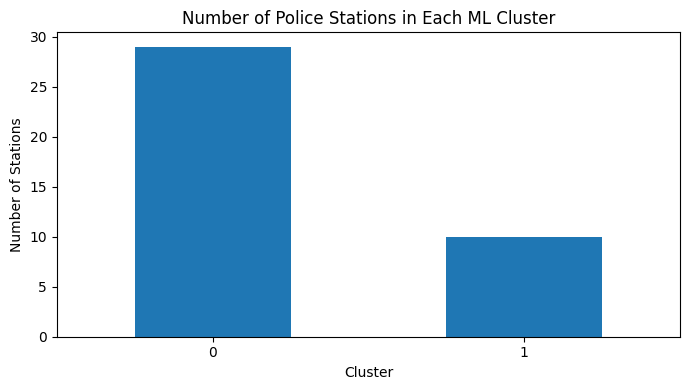

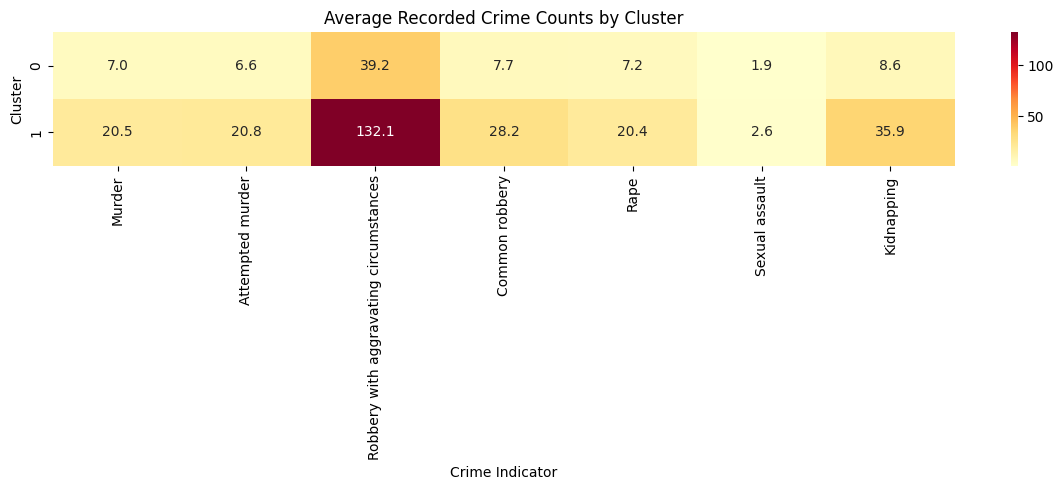

crime_category,Murder,Attempted murder,Robbery with aggravating circumstances,Common robbery,Rape,Sexual assault,Kidnapping
cluster,,,,,,,
0,6.97,6.55,39.21,7.69,7.24,1.93,8.59
1,20.50,20.80,132.10,28.20,20.40,2.60,35.90


In [62]:
crime_columns = [
    "Murder",
    "Attempted murder",
    "Robbery with aggravating circumstances",
    "Common robbery",
    "Rape",
    "Sexual assault",
    "Kidnapping"
]


cluster_sizes = ml_data["cluster"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
cluster_sizes.plot(kind="bar")
plt.title("Number of Police Stations in Each ML Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Stations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


cluster_profiles = ml_data.groupby("cluster")[crime_columns].mean()

plt.figure(figsize=(12, 5))
sns.heatmap(
    cluster_profiles,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd"
)
plt.title("Average Recorded Crime Counts by Cluster")
plt.xlabel("Crime Indicator")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

display(cluster_profiles.round(2))


Saving the Results

The clustering results and model evaluation scores are saved as CSV files so that they can be reused without repeating the entire analysis.

The file ekurhuleni_ml_cluster_results.csv contains the station-level data and its assigned cluster. The file ekurhuleni_model_evaluation.csv contains the silhouette scores for the tested cluster configurations.

Saving these outputs makes the workflow easier to reproduce and provides prepared data for the planned Streamlit dashboard.

The saved files should be regenerated whenever the underlying data, selected features, preprocessing steps, or clustering model changes. This helps ensure that the dashboard displays results consistent with the latest analysis.

In [63]:


for cluster_number in sorted(ml_data["cluster"].unique()):
    stations = ml_data.index[ml_data["cluster"] == cluster_number].tolist()

    print(f"\nCluster {cluster_number} — {len(stations)} stations")
    print(", ".join(stations))


ml_data.to_csv(
    "/content/ekurhuleni_ml_cluster_results.csv",
    index=True
)

print("\nResults saved to ekurhuleni_ml_cluster_results.csv")



Cluster 0 — 29 stations
Actonville, Alberton, Bedfordview, Benoni, Boksburg, Boksburg North, Brackendowns, Brakpan, Crystalpark, Devon, Duduza, Dunnottar, Edenpark, Edenvale, Elsburg, Etwatwa, Katlehong, Katlehong North, Kwa Thema, Nigel, Norkempark, Olifantsfontein, Primrose, Putfontein, Reigerpark, Sebenza, Springs, Tokoza, Zonkizizwe

Cluster 1 — 10 stations
Daveyton, Dawn Park, Germiston, Ivory Park, Kempton Park, Rabie Ridge, Tembisa, Tembisa South, Tsakane, Vosloorus

Results saved to ekurhuleni_ml_cluster_results.csv


In [64]:
evaluation_results = pd.DataFrame({
    "Number of clusters": [2, 3, 4],
    "Silhouette score": [0.413, 0.339, 0.354]
})

display(evaluation_results)

evaluation_results.to_csv(
    "/content/ekurhuleni_model_evaluation.csv",
    index=False
)

print("Model evaluation saved successfully.")


,Number of clusters,Silhouette score
0,2,0.413
1,3,0.339
2,4,0.354


Model evaluation saved successfully.


**Limitations of the Study**

The findings of this project should be interpreted in light of the following limitations:

Victim gender: The available data does not consistently identify whether victims were women. The selected crime indicators are therefore proxies for exploring potential safety concerns, not confirmed counts of crimes against women.

Location accuracy: The coordinates represent police stations rather than the precise locations of crime incidents.

Aggregated data: Crime counts are aggregated by police station and offence category, limiting the level of detail available for analysis.

Population differences: The analysis does not adjust recorded counts for differences in station catchment populations, so higher counts do not necessarily indicate a higher rate of crime.

Reporting differences: Recorded crime may be influenced by reporting behaviour and other factors that are not included in the dataset.

Quarterly coverage: The current completed analysis focuses on April to June 2026. The January to March 2026 dataset has been loaded and filtered but has not yet been fully incorporated into the results.

Clustering limitations: K-Means groups stations according to numerical similarity. The clusters are not verified safety classifications, and the silhouette score is not a measure of predictive accuracy.

Limited model evaluation: Only two, three, and four clusters were compared. Other configurations, features, and validation approaches could produce different results.

These limitations should be considered when interpreting the results or using them to inform further research or safety planning.

**Conclusion**

This project explored selected recorded crime patterns across 39 police stations in Ekurhuleni District using SAPS first-quarter crime statistics. The data was cleaned and filtered, seven crime indicators were selected, and several visualisations were created to examine differences across crime categories and police stations.

An interactive map was also developed using police station coordinates, allowing the station-level results to be explored geographically. K-Means clustering was then applied to the seven selected crime-count features after standardisation.

Of the tested configurations, the two-cluster model achieved the highest silhouette score of 0.413. The resulting groups contained 29 and 10 stations. The group with ten stations had higher mean recorded counts across all seven selected indicators.

These findings demonstrate how data analysis and unsupervised machine learning can be used to explore patterns in recorded crime data. However, the results do not confirm crimes against women, establish individual risk, or predict future incidents.

The next stages are to complete the comparison between the two quarterly datasets, finalise the written interpretation of the results, and develop a Streamlit dashboard to present the analysis interactively.

HOTSPOT Classification using supervised machine learning

Supervised machine learning was used to classify police-station observations as potential recorded sexual-offence hotspots or non-hotspots. The target label was defined using the combined number of recorded rape and sexual-assault cases at each station. A station was labelled as a hotspot when its count exceeded the 75th percentile of station counts for the corresponding month.

The model inputs consisted of previous-calendar-month offence counts, including earlier sexual-offence counts, cyclical month features and police-station identity. The target month's rape and sexual-assault counts were excluded from the input features to prevent target leakage.

The dataset was divided chronologically. Records from 2022–2025 were used for training, while records from 2026 were reserved for testing. A majority-class baseline, Logistic Regression and Random Forest were compared using accuracy, balanced accuracy, precision, recall and F1-score. Training time was also measured.

In the initial evaluation, Logistic Regression achieved an F1-score of approximately 0.535 and recall of approximately 0.628, while Random Forest achieved an F1-score of approximately 0.463. The majority baseline achieved higher accuracy than either classifier but failed to identify any hotspots. Therefore, accuracy alone was not sufficient to evaluate the models.

These results are exploratory. The classification identifies relatively high recorded sexual-offence counts rather than confirmed incidents against women or definitive measures of personal safety. The available data also contains only January–June observations for each year, which limits temporal coverage. Further validation using additional historical data and alternative hotspot definitions is recommended.

In [65]:

# HOTSPOT CLASSIFICATION
# Supervised machine learning using SAPS monthly crime data

import pandas as pd
import numpy as np
import time

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 1. Load the two existing SAPS datasets
q1_path = "/content/drive/MyDrive/2026-2027_-_1st_Quarter_WEB.xlsm"
q4_path = "/content/drive/MyDrive/2025-2026_-_4th_Quarter_WEB.xlsx"

q1_raw = pd.read_excel(q1_path, sheet_name="RAW Data", header=2)
q4_raw = pd.read_excel(q4_path, sheet_name="RAW Data", header=2)


# 2. Standardise column names
def clean_columns(data):
    data = data.copy()
    data.columns = [
        str(c).strip().lower().replace("\n", " ").replace(" ", "_")
        for c in data.columns
    ]
    return data


q1_raw = clean_columns(q1_raw)
q4_raw = clean_columns(q4_raw)


# 3. Keep station-level records from Ekurhuleni
def filter_ekurhuleni(data):
    data = data.copy()

    data["comp_level"] = data["comp_level"].astype(str).str.strip()
    data["district"] = data["district"].astype(str).str.strip()

    data = data[
        (data["comp_level"].str.casefold() == "station") &
        (data["district"].str.casefold() == "ekurhuleni district")
    ].copy()

    data["station"] = data["station"].astype(str).str.strip()
    data["crime_category"] = (
        data["crime_category"].astype(str).str.strip()
    )

    return data


q1_ek = filter_ekurhuleni(q1_raw)
q4_ek = filter_ekurhuleni(q4_raw)


# 4. Convert the monthly columns into a long-format dataset
def extract_monthly_data(data, required_months):
    records = []

    for column in data.columns:
        try:
            # The monthly columns were converted to strings above.
            date_value = pd.to_datetime(
                str(column).replace("_", " "),
                errors="raise"
            )

            if (
                date_value.year >= 2022
                and date_value.year <= 2026
                and date_value.month in required_months
            ):
                temp = data[
                    ["station", "crime_category", column]
                ].copy()

                temp = temp.rename(columns={column: "count"})
                temp["date"] = date_value
                records.append(temp)

        except (ValueError, TypeError):
            continue

    if not records:
        raise ValueError(
            "No monthly columns found. Check the SAPS column names."
        )

    result = pd.concat(records, ignore_index=True)
    result["count"] = pd.to_numeric(
        result["count"], errors="coerce"
    ).fillna(0)

    return result


# Q4 contains January, February and March.
# Q1 contains April, May and June.
monthly_q4 = extract_monthly_data(q4_ek, [1, 2, 3])
monthly_q1 = extract_monthly_data(q1_ek, [4, 5, 6])

monthly_data = pd.concat(
    [monthly_q4, monthly_q1],
    ignore_index=True
)


# 5. Use individual offence categories only
crime_categories = [
    "Murder",
    "Attempted murder",
    "Robbery with aggravating circumstances",
    "Common robbery",
    "Rape",
    "Sexual assault",
    "Kidnapping"
]

monthly_data = monthly_data[
    monthly_data["crime_category"].isin(crime_categories)
].copy()


# 6. Create one row per station per month
station_month = monthly_data.pivot_table(
    index=["station", "date"],
    columns="crime_category",
    values="count",
    aggfunc="sum",
    fill_value=0
).reset_index()

station_month.columns.name = None

for category in crime_categories:
    if category not in station_month.columns:
        station_month[category] = 0

station_month["year"] = station_month["date"].dt.year
station_month["month"] = station_month["date"].dt.month

# The target is built from this month's sexual-offence counts.
station_month["sexual_offence_total"] = (
    station_month["Rape"] + station_month["Sexual assault"]
)


# 7. Define the hotspot label separately for each month.
# A station is labelled 1 when its count is strictly above
# that month's 75th percentile; otherwise, it is labelled 0.
station_month["hotspot"] = (
    station_month.groupby("date")["sexual_offence_total"]
    .transform(lambda values: (
        values > values.quantile(0.75)
    ).astype(int))
)


# 8. Create previous-calendar-month features.
# This avoids treating June and the following January as consecutive.
station_month = station_month.sort_values(
    ["station", "date"]
).reset_index(drop=True)

lag_columns = []

for category in crime_categories:
    lag_name = "previous_" + (
        category.lower().replace(" ", "_")
    )
    lag_columns.append(lag_name)

    previous_month = station_month[
        ["station", "date", category]
    ].copy()

    previous_month["date"] = (
        previous_month["date"] + pd.offsets.MonthBegin(1)
    )

    previous_month = previous_month.rename(
        columns={category: lag_name}
    )

    station_month = station_month.merge(
        previous_month,
        on=["station", "date"],
        how="left"
    )


# 9. Encode month as cyclical features.
station_month["month_sin"] = np.sin(
    2 * np.pi * station_month["month"] / 12
)
station_month["month_cos"] = np.cos(
    2 * np.pi * station_month["month"] / 12
)


# 10. Remove rows without a real previous-calendar-month record.
# This is necessary because July-December are not in these files.
model_data = station_month.dropna(
    subset=lag_columns
).copy()

print("Station-month records before lag filtering:", len(station_month))
print("Usable records after lag filtering:", len(model_data))
print("Stations:", model_data["station"].nunique())
print(
    "Available target months:",
    model_data["date"].nunique()
)


# 11. Use a time-based split, not a random split.
train_data = model_data[model_data["year"] <= 2025].copy()
test_data = model_data[model_data["year"] == 2026].copy()

numeric_features = lag_columns + ["month_sin", "month_cos"]
categorical_features = ["station"]
features = numeric_features + categorical_features

X_train = train_data[features]
y_train = train_data["hotspot"]

X_test = test_data[features]
y_test = test_data["hotspot"]

print("Training observations:", len(train_data))
print("Testing observations:", len(test_data))
print("Hotspots in training data:", int(y_train.sum()))
print("Hotspots in testing data:", int(y_test.sum()))


# 12. Preprocess numerical and categorical features.
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_features
        ),
        (
            "station",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)


# 13. Define baseline and two classifiers.
models = {
    "Majority baseline": DummyClassifier(
        strategy="most_frequent"
    ),
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )
}


# 14. Train, time and evaluate each model.
results = []
predictions = {}

for model_name, estimator in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", estimator)
    ])

    start_time = time.perf_counter()
    pipeline.fit(X_train, y_train)
    training_seconds = time.perf_counter() - start_time

    y_pred = pipeline.predict(X_test)
    predictions[model_name] = y_pred

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, y_pred
        ),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "Training Time (seconds)": training_seconds
    })

    print("\n", "=" * 55)
    print(model_name)
    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(
        y_test, y_pred, zero_division=0
    ))


# 15. Display and save the comparison table.
results_df = pd.DataFrame(results)

display(
    results_df.sort_values("F1 Score", ascending=False)
    .round(3)
)

results_df.to_csv(
    "/content/ekurhuleni_classification_model_results.csv",
    index=False
)


# 16. Save the test predictions for later dashboard use.
test_results = test_data[
    ["station", "date", "sexual_offence_total", "hotspot"]
].copy()

test_results["predicted_hotspot_logistic"] = predictions[
    "Logistic Regression"
]
test_results["predicted_hotspot_random_forest"] = predictions[
    "Random Forest"
]

test_results.to_csv(
    "/content/ekurhuleni_hotspot_classification_predictions.csv",
    index=False
)

display(test_results.head(10))


Station-month records before lag filtering: 1170
Usable records after lag filtering: 975
Stations: 39
Available target months: 25
Training observations: 780
Testing observations: 195
Hotspots in training data: 175
Hotspots in testing data: 43

Majority baseline
Confusion matrix:
[[152   0]
 [ 43   0]]
              precision    recall  f1-score   support

           0       0.78      1.00      0.88       152
           1       0.00      0.00      0.00        43

    accuracy                           0.78       195
   macro avg       0.39      0.50      0.44       195
weighted avg       0.61      0.78      0.68       195


Logistic Regression
Confusion matrix:
[[121  31]
 [ 16  27]]
              precision    recall  f1-score   support

           0       0.88      0.80      0.84       152
           1       0.47      0.63      0.53        43

    accuracy                           0.76       195
   macro avg       0.67      0.71      0.69       195
weighted avg       0.79      0.76   

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score,Training Time (seconds)
1,Logistic Regression,0.759,0.712,0.466,0.628,0.535,0.063
2,Random Forest,0.774,0.655,0.487,0.442,0.463,1.192
0,Majority baseline,0.779,0.500,0.000,0.000,0.000,0.036


,station,date,sexual_offence_total,hotspot,predicted_hotspot_logistic,predicted_hotspot_random_forest
25,Actonville,2026-02-01,2.0,0,0,0
26,Actonville,2026-03-01,2.0,0,0,0
27,Actonville,2026-04-01,3.0,0,0,0
28,Actonville,2026-05-01,0.0,0,0,0
29,Actonville,2026-06-01,0.0,0,0,0
55,Alberton,2026-02-01,4.0,0,0,0
56,Alberton,2026-03-01,3.0,0,0,0
57,Alberton,2026-04-01,4.0,0,0,0
58,Alberton,2026-05-01,4.0,0,0,0
59,Alberton,2026-06-01,1.0,0,0,0
